# 2. From 6-Hour Simulations to 10-Year Clinical Survival (Norris *et al.* Figures 4 & 5)

In Chapter 1, we mapped real DLBCL sequencing data into our 193-species multiscale model and extracted three intracellular concentrations at **6 hours** (`Cdh1`, `cSmac`, and `cCytoC`) to classify each virtual patient into **`AAPP`**, **`AA`**, **`PP`**, or **`other`**.

Now comes the ultimate clinical test: **do those 6-hour virtual cell predictions actually separate which real DLBCL patients survive 10 years on standard R-CHOP chemotherapy from those who relapse early?**

In this final chapter, we analyse the published discovery and validation cohorts from *Norris et al.* (**Blood Cancer Journal**, 2024, 14:105) — **466 real DLBCL patients** — and recreate **Figures 4 and 5** directly from first principles in Julia:
- **Discovery Cohort C1 (`multiscale/C1.csv`, Chapuy *et al.*, $n = 112$ patients)**
- **Validation Cohort C2 (`multiscale/C2.csv`, Lacy *et al.*, $n = 354$ patients)**

---

## Understanding Kaplan–Meier Survival Curves (No Statistics Background Needed!)

In clinical oncology trials, not every patient is followed for the same number of years, and many patients are still alive at the end of the study (**right-censored**). A **Kaplan–Meier curve** estimates the probability $S(t)$ of surviving (or remaining progression-free) past month $t$ without discarding censored patients:

1. Start at month $t = 0$ with $S(0) = 1.0$ (`100%` of patients alive / progression-free).
2. Walk forward in time through every month $t_i$ where at least one event (death or relapse) occurs:
   - Let $n_i$ be the number of patients still **at risk** just before month $t_i$ (neither had an event nor were censored earlier).
   - Let $d_i$ be the number of events at month $t_i$.
   - The fraction who survive past $t_i$ is $(1 - d_i / n_i)$, so the curve steps down:
     $$S(t_i) = S(t_{i-1}) \times \left(1 - \frac{d_i}{n_i}\right)$$
3. **Median survival** is simply the month where the curve crosses **50%** (`0.50`). If the curve stays above 50% throughout follow-up, median survival is **"Not reached"** (good prognosis!).
4. To test whether two survival curves differ more than expected by chance, we compute the **log-rank test** ($\chi^2$ and $p$-value) directly from the observed vs expected events at each time point — in ~25 lines of plain Julia!

---

## Step 1: Load Cohorts C1 & C2 and Write Pure-Julia Kaplan–Meier & Log-Rank Functions

Run the cell below to load `C1.csv` ($n = 112$, times in months) and `C2.csv` ($n = 354$, times in days → converted to months by dividing by `30.4375`), classify every patient using the exact *Norris et al.* mean thresholds (`Cdh1 < mean` for `PP`; `cSmac < mean` and `cCytoC < mean` for `AA`), and inspect the subgroup counts!

In [1]:
using CSV
using DataFrames
using Plots
using Statistics

gr()

# Load Discovery Cohort C1 (Chapuy et al., n=112, time in months)
# and Validation Cohort C2 (Lacy et al., n=354, time in days -> convert to months)
c1 = CSV.read("multiscale/C1.csv", DataFrame)
c2 = CSV.read("multiscale/C2.csv", DataFrame)
c2.OS_months  = Float64.(c2.OS_time)  ./ 30.4375
c2.PFS_months = Float64.(c2.PFS_time) ./ 30.4375

function classify_aapp!(df::DataFrame)
    m_cdh1 = mean(df.Cdh1)
    m_smac = mean(df.cSmac)
    m_cyto = mean(df.cCytoC)
    pp = df.Cdh1 .< m_cdh1
    aa = (df.cSmac .< m_smac) .& (df.cCytoC .< m_cyto)
    df.AAPP_4 = [a && p ? "AAPP" : (a ? "AA" : (p ? "PP" : "other")) for (a, p) in zip(aa, pp)]
    df.AAPP_3 = [a && p ? "AAPP" : ((a || p) ? "AA or PP" : "other") for (a, p) in zip(aa, pp)]
    df.IsAAPP = aa .& pp
    return df
end

classify_aapp!(c1)
classify_aapp!(c2)

# Pure-Julia Kaplan-Meier estimator (returns step coordinates, median survival, 5y & 10y survival)
function kaplan_meier(times::AbstractVector{<:Real}, events::AbstractVector{<:Integer})
    order = sortperm(times)
    ts = Float64.(times[order])
    es = Int.(events[order])
    n  = length(ts)

    t_step = Float64[0.0]
    s_step = Float64[1.0]
    at_risk = n
    S = 1.0
    i = 1
    while i <= n
        t = ts[i]
        d = 0
        c = 0
        while i <= n && ts[i] == t
            if es[i] == 1; d += 1; else; c += 1; end
            i += 1
        end
        if d > 0
            push!(t_step, t); push!(s_step, S)
            S *= (1.0 - d / at_risk)
            push!(t_step, t); push!(s_step, S)
        end
        at_risk -= (d + c)
    end
    push!(t_step, maximum(ts)); push!(s_step, S)

    med_idx = findfirst(x -> x <= 0.5, s_step)
    median_m = isnothing(med_idx) ? nothing : t_step[med_idx]
    surv_at(month) = begin
        j = findlast(x -> x <= month, t_step)
        isnothing(j) ? 1.0 : s_step[j]
    end
    return (t=t_step, S=s_step, n=n, median=median_m, s60=surv_at(60.0), s120=surv_at(120.0))
end

# Complementary error function (Abramowitz & Stegun 7.1.26, error < 1.5e-7) for 1-df chi-square p-values
function approx_erfc(x::Float64)
    t = 1.0 / (1.0 + 0.3275911 * abs(x))
    poly = t * (0.254829592 + t * (-0.284496736 + t * (1.421413741 + t * (-1.453152027 + t * 1.061405429))))
    r = poly * exp(-x * x)
    return x >= 0 ? r : 2.0 - r
end

# Two-group log-rank test (1-df chi-square p-value = erfc(sqrt(chi2 / 2)))
function logrank_pvalue(t1, e1, t2, e2)
    ev_times = sort(unique(vcat(Float64[t for (t, e) in zip(t1, e1) if e == 1],
                                Float64[t for (t, e) in zip(t2, e2) if e == 1])))
    O1 = 0.0; E1 = 0.0; V = 0.0
    for t in ev_times
        n1 = count(>=(t), t1); n2 = count(>=(t), t2)
        d1 = count(i -> t1[i] == t && e1[i] == 1, eachindex(t1))
        d2 = count(i -> t2[i] == t && e2[i] == 1, eachindex(t2))
        n = n1 + n2; d = d1 + d2
        if n > 1 && d > 0
            O1 += d1
            E1 += n1 * d / n
            V  += (n1 * n2 * d * (n - d)) / (n^2 * (n - 1))
        end
    end
    chi2 = V > 0 ? (O1 - E1)^2 / V : 0.0
    pval = approx_erfc(sqrt(chi2 / 2.0))
    return (chi2=chi2, p=pval)
end

println("Cohort C1 (Chapuy, n=", nrow(c1), "): AAPP=", count(c1.IsAAPP),
        " (", round(100 * mean(c1.IsAAPP), digits=1), "%), AA or PP=", count(==("AA or PP"), c1.AAPP_3),
        ", other=", count(==("other"), c1.AAPP_3))
println("Cohort C2 (Lacy,   n=", nrow(c2), "): AAPP=", count(c2.IsAAPP),
        " (", round(100 * mean(c2.IsAAPP), digits=1), "%), AA or PP=", count(==("AA or PP"), c2.AAPP_3),
        ", other=", count(==("other"), c2.AAPP_3))

Cohort C1 (Chapuy, n=112): AAPP=27 (24.1%), AA or PP=75, other=10
Cohort C2 (Lacy,   n=354): AAPP=28 (7.9%), AA or PP=204, other=122


Look at those exact published proportions from *Norris et al.* (2024):
- **Discovery Cohort C1 ($n = 112$):** `24.1%` (`27`) `AAPP`, `67.0%` (`75`) `AA or PP`, `8.9%` (`10`) `other`.
- **Validation Cohort C2 ($n = 354$):** `7.9%` (`28`) `AAPP`, `57.6%` (`204`) `AA or PP`, `34.5%` (`122`) `other`.

---

## Step 2: Recreate Figure 4 — AAPP Predicts Poor Survival in Discovery (C1) and Validation (C2) Cohorts

Now let's plot the Kaplan–Meier curves for **`AAPP`** (red), **`AA or PP`** (orange), and **`other`** (green) in:
- **Left panel:** Discovery Cohort **C1** (Progression-Free Survival, `PFS`, months)
- **Right panel:** Validation Cohort **C2** (Overall Survival, `OS`, months)

=== C1 Discovery (PFS) — Log-rank AAPP vs rest: p = 0.046 ===


Row,Group,N,Median_mo,Surv_5y_pct,Surv_10y_pct
,String,Int64,String,Float64,Float64
1,other,10,NR,80.0,68.6
2,AA or PP,75,NR,66.3,53.4
3,AAPP,27,54.5m,48.1,28.9



=== C2 Validation (OS) — Log-rank AAPP vs rest: p = 0.000203 ===


Row,Group,N,Median_mo,Surv_5y_pct,Surv_10y_pct
,String,Int64,String,Float64,Float64
1,other,122,NR,73.8,59.7
2,AA or PP,204,106.3m,64.6,46.6
3,AAPP,28,10.9m,42.9,24.5


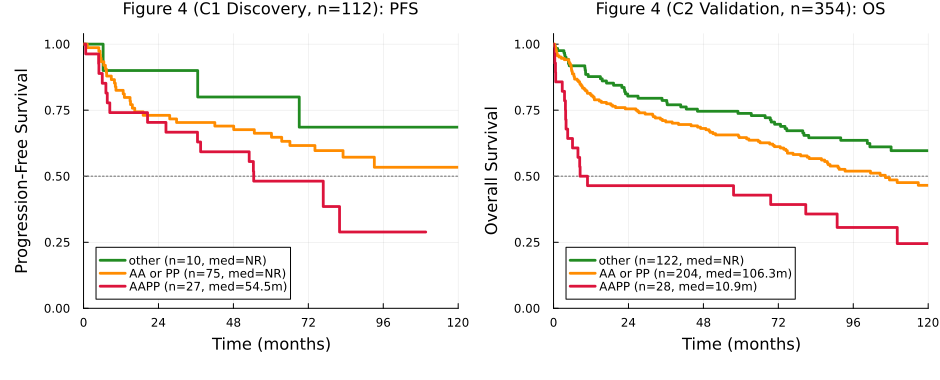

In [2]:
function plot_km_panel(df::DataFrame, time_col::Symbol, status_col::Symbol, group_col::Symbol,
                       groups::Vector{String}, colors::Vector{Symbol}, title_str::String, ylabel_str::String;
                       xlim_m::Float64=120.0)
    p = plot(xlabel="Time (months)", ylabel=ylabel_str, title=title_str, titlefontsize=11,
             xlims=(0, xlim_m), xticks=0:24:Int(xlim_m), ylims=(0, 1.04), legend=:bottomleft)
    hline!(p, [0.5], color=:gray, linestyle=:dot, lw=1.2, label=false)
    rows = NamedTuple[]
    for (g, col) in zip(groups, colors)
        sub = filter(r -> r[group_col] == g, df)
        isempty(sub) && continue
        km = kaplan_meier(sub[!, time_col], sub[!, status_col])
        med_txt = isnothing(km.median) ? "NR" : "$(round(km.median, digits=1))m"
        plot!(p, km.t, km.S, lw=2.8, color=col, label="$(g) (n=$(km.n), med=$(med_txt))")
        push!(rows, (Group=g, N=km.n, Median_mo=med_txt, Surv_5y_pct=round(100 * km.s60, digits=1),
                     Surv_10y_pct=round(100 * km.s120, digits=1)))
    end
    return p, DataFrame(rows)
end

p_c1, tbl_c1 = plot_km_panel(c1, :PFS_time, :PFS_status, :AAPP_3,
                             ["other", "AA or PP", "AAPP"], [:forestgreen, :darkorange, :crimson],
                             "Figure 4 (C1 Discovery, n=112): PFS", "Progression-Free Survival")
lr_c1 = logrank_pvalue(c1.PFS_time[c1.IsAAPP], c1.PFS_status[c1.IsAAPP],
                       c1.PFS_time[.!c1.IsAAPP], c1.PFS_status[.!c1.IsAAPP])

p_c2, tbl_c2 = plot_km_panel(c2, :OS_months, :OS_status, :AAPP_3,
                             ["other", "AA or PP", "AAPP"], [:forestgreen, :darkorange, :crimson],
                             "Figure 4 (C2 Validation, n=354): OS", "Overall Survival")
lr_c2 = logrank_pvalue(c2.OS_months[c2.IsAAPP], c2.OS_status[c2.IsAAPP],
                       c2.OS_months[.!c2.IsAAPP], c2.OS_status[.!c2.IsAAPP])

println("=== C1 Discovery (PFS) — Log-rank AAPP vs rest: p = ", round(lr_c1.p, sigdigits=3), " ===")
display(tbl_c1)
println("\n=== C2 Validation (OS) — Log-rank AAPP vs rest: p = ", round(lr_c2.p, sigdigits=3), " ===")
display(tbl_c2)

plot(p_c1, p_c2, layout=(1, 2), size=(940, 380), left_margin=4Plots.mm, bottom_margin=4Plots.mm)

Look at that dose-dependent prognostic gradient in **both** independent DLBCL cohorts:
- Patients with **neither** signature (**`other`**, green) have the **best survival** (median not reached in both C1 and C2!).
- Patients with **one** signature (**`AA or PP`**, orange) have **intermediate survival**.
- Patients with **both** signatures (**`AAPP`**, red) have the **worst survival** — dropping to a **54.5-month** median PFS in C1 ($p = 0.046$) and a striking **10.9-month** median Overall Survival in the larger C2 validation cohort ($p = 2.0 \times 10^{-4}$)!

---

## Step 3: Recreate Figure 5 — Combining AAPP with Genetic Clusters and Clinical IPI

A major clinical finding of *Norris et al.* (2024) is that **`AAPP` is independent of existing genetic clusters and clinical IPI scores** — meaning combining our 6-hour mechanistic model with standard clinical or genomic risk scores yields far sharper stratification than either method alone!

Let's recreate **Figure 5** in the **C2 Validation Cohort ($n = 354$)** by combining `AAPP` with:
1. **Left panel — Genetic Clusters (`cluster_ICL`):** Poor-prognosis clusters (`MYD88`, `NEC`, `BCL2`) vs good-prognosis (`SGK1`), split by `AAPP` status.
2. **Right panel — Clinical IPI (`IPI`):** `High` / `Intermediate/High` vs `Low` / `Low/Intermediate`, split by `AAPP` status.

=== Combined Genetic Cluster + AAPP (C2 Validation) ===


Row,Group,N,Median_mo,Surv_5y_pct,Surv_10y_pct
,String,Int64,String,Float64,Float64
1,SGK1 (no AAPP),73,NR,78.1,65.3
2,Poor Cluster (no AAPP),253,107.6m,65.2,47.6
3,Poor Cluster + AAPP,24,8.5m,41.7,20.8



=== Combined Clinical IPI + AAPP (C2 Validation) ===


Row,Group,N,Median_mo,Surv_5y_pct,Surv_10y_pct
,String,Int64,String,Float64,Float64
1,Low IPI (no AAPP),161,163.8m,81.4,67.4
2,High IPI (no AAPP),120,74.7m,55.7,34.6
3,Low IPI + AAPP,13,110.1m,69.2,46.2
4,High IPI + AAPP,10,4.5m,20.0,0.0


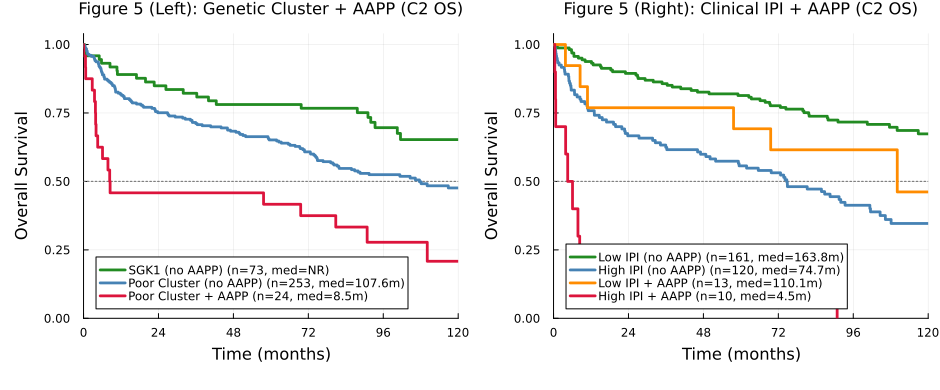

In [3]:
# 1. Combine AAPP with Lacy genetic clusters (poor-prognosis: MYD88, NEC, BCL2 vs SGK1)
poor_clusters = Set(["MYD88", "NEC", "BCL2"])
c2.Cluster_AAPP = [
    let hi = String(r.cluster_ICL) in poor_clusters
        if hi && r.IsAAPP;       "Poor Cluster + AAPP"
        elseif hi && !r.IsAAPP;  "Poor Cluster (no AAPP)"
        elseif !hi && r.IsAAPP;  "SGK1 + AAPP"
        else;                    "SGK1 (no AAPP)"
        end
    end
    for r in eachrow(c2)
]

p_f5_cl, tbl_f5_cl = plot_km_panel(
    c2, :OS_months, :OS_status, :Cluster_AAPP,
    ["SGK1 (no AAPP)", "Poor Cluster (no AAPP)", "Poor Cluster + AAPP"],
    [:forestgreen, :steelblue, :crimson],
    "Figure 5 (Left): Genetic Cluster + AAPP (C2 OS)", "Overall Survival",
)

# 2. Combine AAPP with Clinical IPI (exclude Missing IPI)
c2_ipi = filter(r -> String(r.IPI) != "Missing", c2)
low_ipi = Set(["Low", "Low/Intermediate"])
c2_ipi.IPI_AAPP = [
    let lo = String(r.IPI) in low_ipi
        if lo && !r.IsAAPP;      "Low IPI (no AAPP)"
        elseif lo && r.IsAAPP;   "Low IPI + AAPP"
        elseif !lo && !r.IsAAPP; "High IPI (no AAPP)"
        else;                    "High IPI + AAPP"
        end
    end
    for r in eachrow(c2_ipi)
]

p_f5_ipi, tbl_f5_ipi = plot_km_panel(
    c2_ipi, :OS_months, :OS_status, :IPI_AAPP,
    ["Low IPI (no AAPP)", "High IPI (no AAPP)", "Low IPI + AAPP", "High IPI + AAPP"],
    [:forestgreen, :steelblue, :darkorange, :crimson],
    "Figure 5 (Right): Clinical IPI + AAPP (C2 OS)", "Overall Survival",
)

println("=== Combined Genetic Cluster + AAPP (C2 Validation) ===")
display(tbl_f5_cl)
println("\n=== Combined Clinical IPI + AAPP (C2 Validation) ===")
display(tbl_f5_ipi)

plot(p_f5_cl, p_f5_ipi, layout=(1, 2), size=(940, 390), left_margin=4Plots.mm, bottom_margin=4Plots.mm)

Look at the added prognostic resolution of combining mechanistic simulation with genomic or clinical classifiers:
- In **poor-prognosis genetic clusters + `AAPP`**, median Overall Survival plunges to **8.5 months**, whereas patients in **`SGK1` without `AAPP`** maintain strong long-term survival well past 10 years (`78.1%` 5-year OS, `65.3%` 10-year OS)!
- Combining **Clinical IPI + `AAPP`** spans the full prognostic spectrum: **`High IPI + AAPP`** patients have a median OS of just **4.5 months** (`0.0%` 10-year OS), compared to **163.8 months** (`81.4%` 5-year OS) for **`Low IPI (no AAPP)`** — and even within **Low / Low-Intermediate IPI**, an **`AAPP`** signalling state uncovers a hidden higher-risk subgroup that fails standard R-CHOP.

---

## Interactive Exercise: Does `AAPP` Stratify *Within* Cell-of-Origin Subtypes (`ABC` vs `GCB`)?

Standard DLBCL pathology divides tumours by **Cell of Origin (`COO`)** into **GCB** (Germinal Centre B-cell) and **ABC** (Activated B-cell) subtypes.

**Your task:** Edit `target_coo` below (`"GCB"` or `"ABC"`) to test whether our 6-hour **`AAPP`** biomarker still identifies poor-prognosis patients *within* a single Cell-of-Origin subtype in Cohort C2!

Row,Group,N,Median_mo,Surv_5y_pct,Surv_10y_pct
,String,Int64,String,Float64,Float64
1,Non-AAPP,114,131.6m,71.1,53.2
2,AAPP,6,10.9m,50.0,25.0


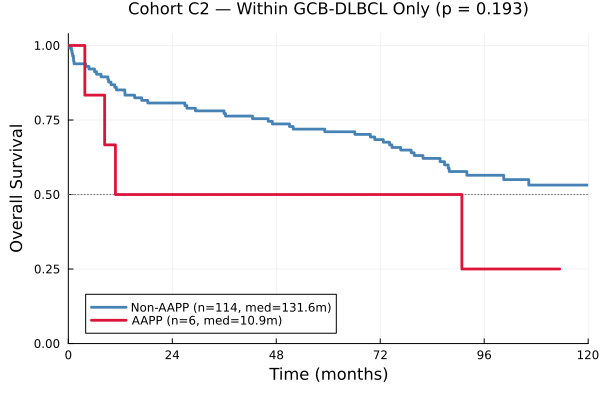

In [4]:
# Exercise: Change target_coo between "GCB" and "ABC" to test AAPP inside each Cell-of-Origin subtype!
target_coo = "GCB"   # <-- Try changing to "ABC"!

sub_coo = filter(r -> String(r.cell_of_origin) == target_coo, c2)
sub_coo.Bin = [r.IsAAPP ? "AAPP" : "Non-AAPP" for r in eachrow(sub_coo)]

lr_coo = logrank_pvalue(sub_coo.OS_months[sub_coo.IsAAPP], sub_coo.OS_status[sub_coo.IsAAPP],
                        sub_coo.OS_months[.!sub_coo.IsAAPP], sub_coo.OS_status[.!sub_coo.IsAAPP])

p_coo, tbl_coo = plot_km_panel(
    sub_coo, :OS_months, :OS_status, :Bin,
    ["Non-AAPP", "AAPP"], [:steelblue, :crimson],
    "Cohort C2 — Within $(target_coo)-DLBCL Only (p = $(round(lr_coo.p, sigdigits=3)))",
    "Overall Survival",
)
display(tbl_coo)
p_coo

````{admonition} Hint
:class: dropdown tip

Run the cell with `target_coo = "GCB"`, note the median OS and log-rank $p$-value, then change it to `target_coo = "ABC"` and re-run. Does `AAPP` predict worse survival in *both* subtypes?
````

````{admonition} Reveal Solution
:class: dropdown note

```julia
panels = []
for coo in ("GCB", "ABC")
    sub = filter(r -> String(r.cell_of_origin) == coo, c2)
    sub.Bin = [r.IsAAPP ? "AAPP" : "Non-AAPP" for r in eachrow(sub)]
    lr = logrank_pvalue(sub.OS_months[sub.IsAAPP], sub.OS_status[sub.IsAAPP],
                        sub.OS_months[.!sub.IsAAPP], sub.OS_status[.!sub.IsAAPP])
    p, tbl = plot_km_panel(sub, :OS_months, :OS_status, :Bin,
                           ["Non-AAPP", "AAPP"], [:steelblue, :crimson],
                           "$(coo)-DLBCL (p = $(round(lr.p, sigdigits=3)))", "Overall Survival")
    println("=== ", coo, "-DLBCL ===")
    display(tbl)
    push!(panels, p)
end
plot(panels..., layout=(1, 2), size=(920, 360), left_margin=4Plots.mm, bottom_margin=4Plots.mm)
```

In *both* `GCB`-DLBCL and `ABC`-DLBCL, `AAPP` patients experience dramatically worse Overall Survival than non-`AAPP` patients of the same subtype — confirming that functional intracellular signalling captures risk missed by traditional cell-of-origin classification!
````

---

## Course Wrap-Up: From a 3-Protein Toy Cascade to Personalised Cancer Modelling

Look at the full progression you have built across all seven tutorials:
1. **Tutorial 1:** Three-species biochemical cascade ($\emptyset \to A \to B \to C \to \emptyset$) and the CSV-to-ODE workflow.
2. **Tutorial 2:** Modifiers, transcriptional induction, and NF-κB / IκB negative feedback.
3. **Tutorial 3:** `CSV2Julia` rules & modes (`inline`, `scan`, `param`), dynamic time-dependent inputs, and the 101-species NF-κB model.
4. **Tutorial 4:** Combining multiple CSV modules into the 150-species BCR–TLR–NF-κB Tri-Model and recreating Figure 5 of *Jayawant et al.*
5. **Tutorial 5:** Single-cell fate clocks — Apoptosis (`BCL2` scan, Figure 1B) and Cell Cycle (`c-MYC` scan with division callbacks, Figure 1E) of *Norris et al.*
6. **Tutorial 6:** Wiring all five modules into the **193-species agent-based multiscale model** to explain **MYC + BCL2** synergy vs **MYC + BCL6** (Figure 2).
7. **Tutorial 7:** Mapping real patient genomic data into **virtual avatars** to predict **10-year DLBCL clinical survival** and test targeted therapies (Figures 3–5).

You now have the complete computational foundation used in the Mitchell Lab's published B-cell lymphoma models!